In [1]:
! pip install gensim

In [2]:
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from matplotlib import pyplot as plt


- **size**: (default 100) The number of dimensions of the embedding, e.g. the length of the dense vector to represent each token (word).
- **window**: (default 5) The maximum distance between a target word and words around the target word.
- **min_count**: (default 5) The minimum count of words to consider when training the model; words with an occurrence less than this count will be ignored.
- **workers**: (default 3) The number of threads to use while training.
- **sg**: (default 0 or CBOW) The training algorithm, either CBOW (0) or skip gram (1).


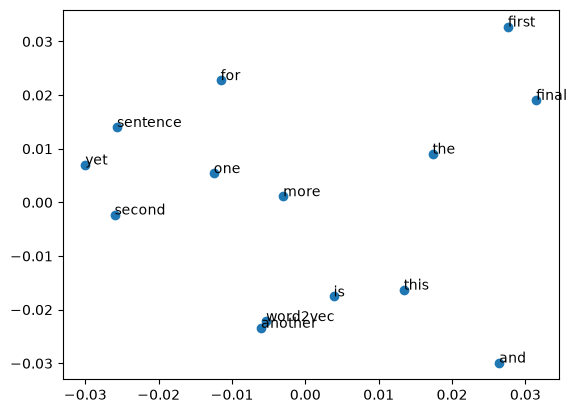

In [3]:
# Definisci i dati di addestramento
sentences = [['this', 'is', 'the', 'first', 'sentence', 'for', 'word2vec'],
             ['this', 'is', 'the', 'second', 'sentence'],
             ['yet', 'another', 'sentence'],
             ['one', 'more', 'sentence'],
             ['and', 'the', 'final', 'sentence']]

# Creiamo e addestriamo il modello Word2Vec.
model = Word2Vec(
    sentences,
    
    # Ogni parola sarà rappresentata da un vettore
    # composto da 100 numeri.
    vector_size=100,
    
    # Consideriamo le parole che si trovano entro una
    # finestra di 5 parole rispetto alla parola analizzata.
    window=5,
    
    # Manteniamo nel vocabolario anche le parole che
    # compaiono una sola volta.
    min_count=1,
    
    # sg=0 significa che utilizziamo l'architettura CBOW.
    # CBOW cerca di prevedere una parola a partire
    # dalle parole che la circondano.
    sg=0
)

# Estrai i vettori delle parole per il PCA
# Recuperiamo tutte le parole presenti nel vocabolario
# che Word2Vec ha costruito durante l'addestramento.
words = list(model.wv.index_to_key)


# Per ogni parola recuperiamo il relativo embedding.
#
# Esempio concettuale:
#
# "gatto" → [0.12, -0.45, 0.31, ...]
# "cane"  → [0.18, -0.39, 0.27, ...]
#
# Ogni vettore contiene 100 valor
X = [model.wv[word] for word in words]

# Adatta un modello PCA a 2D sui vettori

# I nostri embedding hanno 100 dimensioni.
# Non possiamo visualizzarli direttamente in un normale
# grafico 2D/3D.
#
# Per questo utilizziamo PCA per trasformare:
#
#       100 dimensioni → 3 dimensioni
#
# ATTENZIONE:
# PCA NON misura la similarità tra le parole.
# Serve qui principalmente per poter visualizzare
# gli embedding.
pca = PCA(n_components=3)
result = pca.fit_transform(X)

# Crea un grafico a dispersione delle proiezioni
plt.scatter(result[:, 0], result[:, 1])

# Aggiungi le etichette per ciascuna parola
for i, word in enumerate(words):
    plt.annotate(word, xy=(result[i, 0], result[i, 1]))

plt.show()


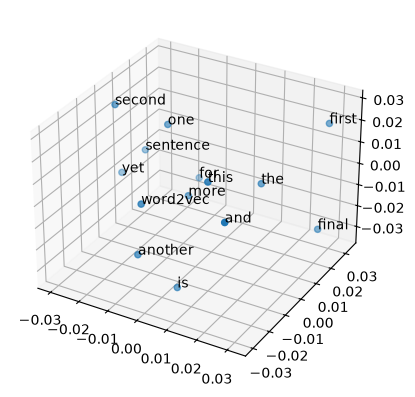

In [6]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    result[:, 0],
    result[:, 1],
    result[:, 2]
)

for i, word in enumerate(words):
    ax.text(
        result[i, 0],
        result[i, 1],
        result[i, 2],
        word
    )

plt.show()